# Pandas

The `numpy` module is excellent for numerical computations, but to handle missing data or arrays with mixed types takes more work. The `pandas` module is currently the most widely used tool for data manipulation, providing high-performance, easy-to-use data structures and advanced data analysis tools.

In particular `pandas` features:

* A fast and efficient "DataFrame" object for data manipulation with integrated indexing;
* Tools for reading and writing data between in-memory data structures and different formats (CSV, Excel, SQL, HDF5);
* Intelligent data alignment and integrated handling of missing data;
* Intelligent label-based slicing, fancy indexing, and subsetting of large data sets;
* Aggregating or transforming data with a powerful "group-by" engine; 
* High performance merging and joining of data sets;
* Hierarchical axis indexing provides an intuitive way of working with high-dimensional data in a lower-dimensional data structure;
* Time series-functionalities;
* Highly optimized for performance, with critical code paths written in Cython or C.


In [1]:
import pandas as pd
import numpy as np

## Series

Series are completely equivalent to 1D array but with axis labels and the possibility to store heterogeneous elements. Of paramount importance are the time-series, used to define time evolutions of a phenomenon. 


In [2]:
from string import ascii_lowercase as letters

# Creating a series, accessing indexes, values and values by their index 
xs = pd.Series(np.arange(10)*0.5, index=tuple(letters[:10]))
print ("xs:", xs,'\n')
print ("xs indexes:",xs.index,'\n')
# Values of the Series are actually a numpy array
print ("xs values:", xs.values, type(xs.values),'\n')
print (xs['f'], xs.f, xs.h, '\n')
print (xs[['d', 'f', 'h']], '\n')
print (type(xs[['d', 'f', 'h']]), '\n')

xs: a    0.0
b    0.5
c    1.0
d    1.5
e    2.0
f    2.5
g    3.0
h    3.5
i    4.0
j    4.5
dtype: float64 

xs indexes: Index(['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j'], dtype='object') 

xs values: [0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5] <class 'numpy.ndarray'> 

2.5 2.5 3.5 

d    1.5
f    2.5
h    3.5
dtype: float64 

<class 'pandas.core.series.Series'> 



In [3]:
# Extracting elements and operations: same as numpy array
print (xs[:3],'\n')
print (xs[7:], '\n')
print (xs[::3], '\n')
print (xs[xs>3], '\n')
print (np.exp(xs), '\n')
print (np.mean(xs), np.std(xs), '\n')

a    0.0
b    0.5
c    1.0
dtype: float64 

h    3.5
i    4.0
j    4.5
dtype: float64 

a    0.0
d    1.5
g    3.0
j    4.5
dtype: float64 

h    3.5
i    4.0
j    4.5
dtype: float64 

a     1.000000
b     1.648721
c     2.718282
d     4.481689
e     7.389056
f    12.182494
g    20.085537
h    33.115452
i    54.598150
j    90.017131
dtype: float64 

2.25 1.4361406616345072 



In [4]:
# Series can be created from python dictionary too.
# Not that the elements can be whatever!
d = {'b' : 1, 'a' : 'cat', 'c' : [2,3]}
pd.Series(d)



b         1
a       cat
c    [2, 3]
dtype: object

A key difference between Series and ndarray is that operations between Series automatically align the data based on label. Thus, you can write computations without considering whether the Series involved have the same labels.

In [5]:
s = pd.Series(np.random.randn(5), index=tuple(letters[:5]))
print(s)
s = s[1:] + s[:-1]
print(s)

a    0.207815
b    0.347253
c    0.619992
d   -1.002790
e    0.001932
dtype: float64
a         NaN
b    0.694506
c    1.239984
d   -2.005579
e         NaN
dtype: float64


### Time series

Time series are very often used to profile the behaviour of a quantity as a function of time. Pandas has a special index for that, `DatetimeIndex`, that can be created e.g. with the function `pd.data_range()`

In [6]:
# to define a date, the datetime module is very useful
import datetime as dt
date = dt.date.today()
print(date)

date = dt.datetime(2026,11,18,10,45,10,15)
print (date)

# otherwise, several notations are interpreted too
date = 'Nov 18 2026'
# or alternatively
#date = '18/11/2026 10:45:00'
print (date)

days = pd.date_range(date, periods=7, freq='D')        #   => freq = 'D' stands for days
print (days)

seconds = pd.date_range(date, periods=3600, freq='s')
print (seconds)


2026-11-18
2026-11-18 10:45:10.000015
Nov 18 2026
DatetimeIndex(['2026-11-18', '2026-11-19', '2026-11-20', '2026-11-21',
               '2026-11-22', '2026-11-23', '2026-11-24'],
              dtype='datetime64[ns]', freq='D')
DatetimeIndex(['2026-11-18 00:00:00', '2026-11-18 00:00:01',
               '2026-11-18 00:00:02', '2026-11-18 00:00:03',
               '2026-11-18 00:00:04', '2026-11-18 00:00:05',
               '2026-11-18 00:00:06', '2026-11-18 00:00:07',
               '2026-11-18 00:00:08', '2026-11-18 00:00:09',
               ...
               '2026-11-18 00:59:50', '2026-11-18 00:59:51',
               '2026-11-18 00:59:52', '2026-11-18 00:59:53',
               '2026-11-18 00:59:54', '2026-11-18 00:59:55',
               '2026-11-18 00:59:56', '2026-11-18 00:59:57',
               '2026-11-18 00:59:58', '2026-11-18 00:59:59'],
              dtype='datetime64[ns]', length=3600, freq='s')


To learn more about the frequency strings, please see this [link](http://pandas.pydata.org/pandas-docs/stable/timeseries.html#offset-aliases)


Timestamped data is the most basic type of time series data that associates values with points in time. For pandas objects it means using the points in time.

functions like `pd.to_datetime` can be used, for instance, when reading information as string from a dataset.

Timestamp is the pandas equivalent of python’s Datetime and is interchangeable with it in most cases. 

In [7]:
tstamp = pd.Timestamp(dt.datetime(2020, 11, 9))

# internally it counts the nanoseconds from January 1st 19
#tstamp = pd.Timestamp(dt.datetime(1970, 1, 1, 0, 0, 0, 1))
print(tstamp.value)

# when creating a timestamp the format can be explicitly passed
ts = pd.to_datetime('2010/11/12', format='%Y/%m/%d')
print (type(ts))
print (ts.value)
ts = pd.to_datetime('12-11-2010 00:00', format='%d-%m-%Y %H:%M')
print (ts)
print (ts.value)



1604880000000000000
<class 'pandas._libs.tslibs.timestamps.Timestamp'>
1289520000000000000
2010-11-12 00:00:00
1289520000000000000


A standard series can be created and (range of) elements can be used as indexes

In [8]:
tseries = pd.Series(np.random.normal(10, 1, len(days)), index=days)
# Extracting elements
print (tseries[0:4], '\n')
print (tseries['2026-11-18':'2026-12-01'], '\n') # Note - includes end time


2026-11-18    10.150714
2026-11-19     9.414798
2026-11-20     9.512566
2026-11-21     9.892795
Freq: D, dtype: float64 

2026-11-18    10.150714
2026-11-19     9.414798
2026-11-20     9.512566
2026-11-21     9.892795
2026-11-22     9.374482
2026-11-23     8.709415
2026-11-24     9.106273
Freq: D, dtype: float64 



`pd.to_datetime` can also be used to create a `DatetimeIndex`:

In [9]:
pd.to_datetime([1, 2, 3, 4], unit='D', origin=pd.Timestamp('1980-02-03'))

DatetimeIndex(['1980-02-04', '1980-02-05', '1980-02-06', '1980-02-07'], dtype='datetime64[ns]', freq=None)

## DataFrame

A pandas DataFrame is like a simple tabular spreadsheet. For future reference (or for people already familiar with R), a pandas DataFrame is very similar to the R DataFrame.

Each column in a DataFrame is a Series object.

The element can be whatever, missing data are dealt with too (as NaN)

### DataFrame creation

A DataFrame can be created implicitly, with, e.g., a DatatimeIndex object as index:

In [10]:
entries=10
dates=pd.date_range('11/18/2026 10:45:00',freq='h', periods=entries)
df = pd.DataFrame(np.random.randn(entries,4), index=dates, columns=['A','B','C','D'])
df


,A,B,C,D
2026-11-18 10:45:00,0.684167,-0.220162,-0.310299,-0.645074
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,-0.570749
2026-11-18 12:45:00,1.289039,1.849558,0.223138,0.845665
2026-11-18 13:45:00,-0.048199,1.488394,-1.480614,-0.440466
2026-11-18 14:45:00,0.034216,-0.543686,0.243684,-2.008601
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,0.086741
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,1.326113
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,-0.135081
2026-11-18 18:45:00,0.429565,0.745063,0.381374,-0.856236
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,0.340309


or by means of a dictionary:

In [11]:
df2 = pd.DataFrame(
    { 'A' : 1.,
      'B' : pd.Timestamp('20130102'),
      'C' : pd.Series(1,index=range(4),dtype='float32'),
      'D' : np.arange(7,11),
      'E' : pd.Categorical(["test","train","test","train"]),
    }
    )
df2

# check what happens if D and E had different lenghts 

,A,B,C,D,E
0,1.0,2013-01-02,1.0,7,test
1,1.0,2013-01-02,1.0,8,train
2,1.0,2013-01-02,1.0,9,test
3,1.0,2013-01-02,1.0,10,train


### Viewing Data

In [12]:
df.head(3)

,A,B,C,D
2026-11-18 10:45:00,0.684167,-0.220162,-0.310299,-0.645074
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,-0.570749
2026-11-18 12:45:00,1.289039,1.849558,0.223138,0.845665


In [13]:
df.tail(4)

,A,B,C,D
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,1.326113
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,-0.135081
2026-11-18 18:45:00,0.429565,0.745063,0.381374,-0.856236
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,0.340309


In [14]:
df.index

DatetimeIndex(['2026-11-18 10:45:00', '2026-11-18 11:45:00',
               '2026-11-18 12:45:00', '2026-11-18 13:45:00',
               '2026-11-18 14:45:00', '2026-11-18 15:45:00',
               '2026-11-18 16:45:00', '2026-11-18 17:45:00',
               '2026-11-18 18:45:00', '2026-11-18 19:45:00'],
              dtype='datetime64[ns]', freq='h')

In [15]:
df.columns

Index(['A', 'B', 'C', 'D'], dtype='object')

In [16]:
df.values

array([[ 0.68416661, -0.22016231, -0.31029947, -0.64507388],
       [ 0.15185585,  0.87632979, -0.02592262, -0.57074866],
       [ 1.28903877,  1.84955795,  0.22313786,  0.84566527],
       [-0.04819946,  1.4883937 , -1.48061426, -0.44046639],
       [ 0.03421648, -0.54368596,  0.24368387, -2.00860063],
       [ 2.34266929,  0.41836414, -0.1396359 ,  0.08674052],
       [-1.09650507, -0.64508511,  0.74399043,  1.32611291],
       [ 1.42362975, -0.1119414 ,  1.32654383, -0.1350809 ],
       [ 0.42956499,  0.74506336,  0.3813736 , -0.85623639],
       [ 1.92660205, -0.18074117, -1.45511943,  0.34030918]])

In [17]:
df.describe()

,A,B,C,D
count,10.000000,10.000000,10.000000,10.000000
mean,0.713704,0.367609,-0.049286,-0.205738
std,1.036875,0.855590,0.880001,0.936633
min,-1.096505,-0.645085,-1.480614,-2.008601
25%,0.063626,-0.210307,-0.267634,-0.626493
50%,0.556866,0.153211,0.098608,-0.287774
75%,1.389982,0.843513,0.346951,0.276917
max,2.342669,1.849558,1.326544,1.326113


In [18]:
df.T

,2026-11-18 10:45:00,2026-11-18 11:45:00,2026-11-18 12:45:00,2026-11-18 13:45:00,2026-11-18 14:45:00,2026-11-18 15:45:00,2026-11-18 16:45:00,2026-11-18 17:45:00,2026-11-18 18:45:00,2026-11-18 19:45:00
A,0.684167,0.151856,1.289039,-0.048199,0.034216,2.342669,-1.096505,1.423630,0.429565,1.926602
B,-0.220162,0.876330,1.849558,1.488394,-0.543686,0.418364,-0.645085,-0.111941,0.745063,-0.180741
C,-0.310299,-0.025923,0.223138,-1.480614,0.243684,-0.139636,0.743990,1.326544,0.381374,-1.455119
D,-0.645074,-0.570749,0.845665,-0.440466,-2.008601,0.086741,1.326113,-0.135081,-0.856236,0.340309


In [19]:
df.sort_index(axis=0,ascending=False)

,A,B,C,D
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,0.340309
2026-11-18 18:45:00,0.429565,0.745063,0.381374,-0.856236
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,-0.135081
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,1.326113
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,0.086741
2026-11-18 14:45:00,0.034216,-0.543686,0.243684,-2.008601
2026-11-18 13:45:00,-0.048199,1.488394,-1.480614,-0.440466
2026-11-18 12:45:00,1.289039,1.849558,0.223138,0.845665
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,-0.570749
2026-11-18 10:45:00,0.684167,-0.220162,-0.310299,-0.645074


In [20]:
df.sort_values(by="C")

,A,B,C,D
2026-11-18 13:45:00,-0.048199,1.488394,-1.480614,-0.440466
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,0.340309
2026-11-18 10:45:00,0.684167,-0.220162,-0.310299,-0.645074
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,0.086741
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,-0.570749
2026-11-18 12:45:00,1.289039,1.849558,0.223138,0.845665
2026-11-18 14:45:00,0.034216,-0.543686,0.243684,-2.008601
2026-11-18 18:45:00,0.429565,0.745063,0.381374,-0.856236
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,1.326113
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,-0.135081


## Selection

### Getting slices

The following show how to get part of the DataFrame (i.e. not just the elements)

In [21]:
## standard and safe
print (df['A'],'\n')

## equivalent but dangerous (imagine blank spaces in the name of the column..)
print (df.A)

2026-11-18 10:45:00    0.684167
2026-11-18 11:45:00    0.151856
2026-11-18 12:45:00    1.289039
2026-11-18 13:45:00   -0.048199
2026-11-18 14:45:00    0.034216
2026-11-18 15:45:00    2.342669
2026-11-18 16:45:00   -1.096505
2026-11-18 17:45:00    1.423630
2026-11-18 18:45:00    0.429565
2026-11-18 19:45:00    1.926602
Freq: h, Name: A, dtype: float64 

2026-11-18 10:45:00    0.684167
2026-11-18 11:45:00    0.151856
2026-11-18 12:45:00    1.289039
2026-11-18 13:45:00   -0.048199
2026-11-18 14:45:00    0.034216
2026-11-18 15:45:00    2.342669
2026-11-18 16:45:00   -1.096505
2026-11-18 17:45:00    1.423630
2026-11-18 18:45:00    0.429565
2026-11-18 19:45:00    1.926602
Freq: h, Name: A, dtype: float64


In [22]:
# selecting rows by counting
print (df[0:3])

# or by index
print (df["2026-11-18 10:45:00":"2026-11-18 12:45:00"])

                            A         B         C         D
2026-11-18 10:45:00  0.684167 -0.220162 -0.310299 -0.645074
2026-11-18 11:45:00  0.151856  0.876330 -0.025923 -0.570749
2026-11-18 12:45:00  1.289039  1.849558  0.223138  0.845665
                            A         B         C         D
2026-11-18 10:45:00  0.684167 -0.220162 -0.310299 -0.645074
2026-11-18 11:45:00  0.151856  0.876330 -0.025923 -0.570749
2026-11-18 12:45:00  1.289039  1.849558  0.223138  0.845665


### Selection by label

In [23]:
# getting a cross section (part of the DataFrame) using a label
df.loc[dates[0]]

A    0.684167
B   -0.220162
C   -0.310299
D   -0.645074
Name: 2026-11-18 10:45:00, dtype: float64

In [24]:
# selecting on a multi-axis by label:
df.loc[:"2026-11-18 12:45:00",['A','B']]
#a=df.loc[:,['A','B']]

,A,B
2026-11-18 10:45:00,0.684167,-0.220162
2026-11-18 11:45:00,0.151856,0.876330
2026-11-18 12:45:00,1.289039,1.849558


In [25]:
# showing label slicing, both endpoints are included:
df.loc['2026-11-18 14:45:00':'2026-11-18 16:45:00',['A','B']]

,A,B
2026-11-18 14:45:00,0.034216,-0.543686
2026-11-18 15:45:00,2.342669,0.418364
2026-11-18 16:45:00,-1.096505,-0.645085


In [26]:
# getting an individual element
print (df.loc[dates[1],'A'])

# equivalently
print (df.at[dates[1],'A'])

0.15185585043592628
0.15185585043592628


### Selecting by position

In [27]:
# select via the position of the passed integers:
print (df.iloc[3],'\n')

# notation similar to numpy/python
print (df.iloc[3:5,0:2])

A   -0.048199
B    1.488394
C   -1.480614
D   -0.440466
Name: 2026-11-18 13:45:00, dtype: float64 

                            A         B
2026-11-18 13:45:00 -0.048199  1.488394
2026-11-18 14:45:00  0.034216 -0.543686


In [28]:
# selecting raws 1,2 and 4 for columns 0 and 2
df.iloc[[1,2,4],[0,2]]

,A,C
2026-11-18 11:45:00,0.151856,-0.025923
2026-11-18 12:45:00,1.289039,0.223138
2026-11-18 14:45:00,0.034216,0.243684


In [29]:
# slicing rows explicitly
print (df.iloc[1:3,:],'\n')

# slicing columns explicitly
print (df.iloc[:,1:3])

# selecting an individual element by position
print(df.iloc[1,1])

                            A         B         C         D
2026-11-18 11:45:00  0.151856  0.876330 -0.025923 -0.570749
2026-11-18 12:45:00  1.289039  1.849558  0.223138  0.845665 

                            B         C
2026-11-18 10:45:00 -0.220162 -0.310299
2026-11-18 11:45:00  0.876330 -0.025923
2026-11-18 12:45:00  1.849558  0.223138
2026-11-18 13:45:00  1.488394 -1.480614
2026-11-18 14:45:00 -0.543686  0.243684
2026-11-18 15:45:00  0.418364 -0.139636
2026-11-18 16:45:00 -0.645085  0.743990
2026-11-18 17:45:00 -0.111941  1.326544
2026-11-18 18:45:00  0.745063  0.381374
2026-11-18 19:45:00 -0.180741 -1.455119
0.8763297929126719


### Boolean index

Very powerful way of filtering out data with certain features. Notation is very similar to numpy arrays.

In [30]:
# Filter by a boolean condition on the values of a single column
df[df['B'] > 0]

,A,B,C,D
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,-0.570749
2026-11-18 12:45:00,1.289039,1.849558,0.223138,0.845665
2026-11-18 13:45:00,-0.048199,1.488394,-1.480614,-0.440466
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,0.086741
2026-11-18 18:45:00,0.429565,0.745063,0.381374,-0.856236


In [31]:
# Selecting on the basis of boolean conditions applied to the whole DataFrame
df[df>0]

# a DataFrame with the same shape is returned, with NaN's where condition is not met

,A,B,C,D
2026-11-18 10:45:00,0.684167,NaN,NaN,NaN
2026-11-18 11:45:00,0.151856,0.876330,NaN,NaN
2026-11-18 12:45:00,1.289039,1.849558,0.223138,0.845665
2026-11-18 13:45:00,NaN,1.488394,NaN,NaN
2026-11-18 14:45:00,0.034216,NaN,0.243684,NaN
2026-11-18 15:45:00,2.342669,0.418364,NaN,0.086741
2026-11-18 16:45:00,NaN,NaN,0.743990,1.326113
2026-11-18 17:45:00,1.423630,NaN,1.326544,NaN
2026-11-18 18:45:00,0.429565,0.745063,0.381374,NaN
2026-11-18 19:45:00,1.926602,NaN,NaN,0.340309


### Setting

Combination of selection and setting of values

In [32]:
# setting values by label (same as by position)
df.at[dates[0],'A'] = 0

# setting and assigning a numpy array
df.loc[:,'D'] = np.array([5] * len(df))

# defining a brend new column
df['E'] = np.arange(len(df))*0.5

# defining a brend new column by means of a pd.Series: indexes must be the same!
df['E prime'] = pd.Series(np.arange(len(df))*2, index=df.index)

df

,A,B,C,D,E,E prime
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,5.0,0.5,2
2026-11-18 12:45:00,1.289039,1.849558,0.223138,5.0,1.0,4
2026-11-18 13:45:00,-0.048199,1.488394,-1.480614,5.0,1.5,6
2026-11-18 14:45:00,0.034216,-0.543686,0.243684,5.0,2.0,8
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,10
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,5.0,3.0,12
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,14
2026-11-18 18:45:00,0.429565,0.745063,0.381374,5.0,4.0,16
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,5.0,4.5,18


In [33]:
def dcos(theta):
    theta = theta*(np.pi/180)
    return np.cos(theta)
 
df['cosine'] = pd.Series(df["E"].apply(dcos), index=df.index)
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0,1.000000
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,5.0,0.5,2,0.999962
2026-11-18 12:45:00,1.289039,1.849558,0.223138,5.0,1.0,4,0.999848
2026-11-18 13:45:00,-0.048199,1.488394,-1.480614,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.034216,-0.543686,0.243684,5.0,2.0,8,0.999391
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,5.0,3.0,12,0.998630
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,14,0.998135
2026-11-18 18:45:00,0.429565,0.745063,0.381374,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,5.0,4.5,18,0.996917


In [34]:
# another example of global setting
df2=df.copy()

df2[df2>0] = -df2
df2

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,-5.0,0.0,0,-1.000000
2026-11-18 11:45:00,-0.151856,-0.876330,-0.025923,-5.0,-0.5,-2,-0.999962
2026-11-18 12:45:00,-1.289039,-1.849558,-0.223138,-5.0,-1.0,-4,-0.999848
2026-11-18 13:45:00,-0.048199,-1.488394,-1.480614,-5.0,-1.5,-6,-0.999657
2026-11-18 14:45:00,-0.034216,-0.543686,-0.243684,-5.0,-2.0,-8,-0.999391
2026-11-18 15:45:00,-2.342669,-0.418364,-0.139636,-5.0,-2.5,-10,-0.999048
2026-11-18 16:45:00,-1.096505,-0.645085,-0.743990,-5.0,-3.0,-12,-0.998630
2026-11-18 17:45:00,-1.423630,-0.111941,-1.326544,-5.0,-3.5,-14,-0.998135
2026-11-18 18:45:00,-0.429565,-0.745063,-0.381374,-5.0,-4.0,-16,-0.997564
2026-11-18 19:45:00,-1.926602,-0.180741,-1.455119,-5.0,-4.5,-18,-0.996917


### Are you dealing with a Copy or a View?

In general is hard to tell..

In [35]:
dfd = pd.DataFrame({'a': [1, 2, 3], 'b': [4, 5, 6]})

# This is likely a view
subset = dfd.loc[0:1, 'a']  
subset[0] = 100  # May affect `df`

print (dfd)

# This is a copy
subset = dfd.loc[[0, 1], 'a']  
subset[0] = 200  # Does NOT affect `df`

print (dfd)



     a  b
0  100  4
1    2  5
2    3  6
     a  b
0  100  4
1    2  5
2    3  6


The behaviour depend on the version of Pandas and on the version of Numpy that given version of Pandas depends upon. Since Pandas 1.5 "Copy-on-Write" (CoW) is (optionally) available and as of Pandas 3.0 will be the default. 

With CoW chained assignemt will never work; in the following example, the view `dfd["a"]` and `df` itself are modified in one step. This will lead to a `ChainedAssignemntError`  

In [36]:
dfd["a"][dfd["b"] > 5] = 100
dfd

/var/folders/yf/kb__k7j15_x42qh08yf_mf300000gn/T/ipykernel_10394/449088826.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  dfd["a"][dfd["b"] > 5] = 100


,a,b
0,100,4
1,2,5
2,100,6


With copy on write this can be done by using `loc`

In [37]:
dfd.loc[dfd["b"] > 5, "a"] = 200
dfd

,a,b
0,100,4
1,2,5
2,200,6


### Dropping

N.B.: dropping doesn't act permanently on the DataFrame, i.e. to get that do :
```python
df = df.drop(....)
```

In [38]:
# Dropping by column
df.drop(['E prime'], axis=1)

#which is equivalent to
new_df=df.drop(columns=['E prime'])
new_df

,A,B,C,D,E,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,1.000000
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,5.0,0.5,0.999962
2026-11-18 12:45:00,1.289039,1.849558,0.223138,5.0,1.0,0.999848
2026-11-18 13:45:00,-0.048199,1.488394,-1.480614,5.0,1.5,0.999657
2026-11-18 14:45:00,0.034216,-0.543686,0.243684,5.0,2.0,0.999391
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,0.999048
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,5.0,3.0,0.998630
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,0.998135
2026-11-18 18:45:00,0.429565,0.745063,0.381374,5.0,4.0,0.997564
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,5.0,4.5,0.996917


In [39]:
# Dropping by raws
# safe and always working
df.drop(df.index[[1,2,3,4]])

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0,1.000000
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,5.0,3.0,12,0.998630
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,14,0.998135
2026-11-18 18:45:00,0.429565,0.745063,0.381374,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,5.0,4.5,18,0.996917


In [40]:
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0,1.000000
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,5.0,0.5,2,0.999962
2026-11-18 12:45:00,1.289039,1.849558,0.223138,5.0,1.0,4,0.999848
2026-11-18 13:45:00,-0.048199,1.488394,-1.480614,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.034216,-0.543686,0.243684,5.0,2.0,8,0.999391
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,5.0,3.0,12,0.998630
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,14,0.998135
2026-11-18 18:45:00,0.429565,0.745063,0.381374,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,5.0,4.5,18,0.996917


In [41]:
# something like df.drop('index_name') 
# would work but the type of index must be specificed, 
# in particular with DatetimeIndex
df.drop(pd.to_datetime("2026-11-18 18:45:00"))

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0,1.000000
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,5.0,0.5,2,0.999962
2026-11-18 12:45:00,1.289039,1.849558,0.223138,5.0,1.0,4,0.999848
2026-11-18 13:45:00,-0.048199,1.488394,-1.480614,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.034216,-0.543686,0.243684,5.0,2.0,8,0.999391
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,5.0,3.0,12,0.998630
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,14,0.998135
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,5.0,4.5,18,0.996917


## Missing data

pandas primarily uses the value np.nan to represent missing data. It is by default not included in computations.

In [42]:
df_wNan = df[df>-0.5]
df_wNan

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0,1.000000
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,5.0,0.5,2,0.999962
2026-11-18 12:45:00,1.289039,1.849558,0.223138,5.0,1.0,4,0.999848
2026-11-18 13:45:00,-0.048199,1.488394,NaN,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.034216,NaN,0.243684,5.0,2.0,8,0.999391
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,10,0.999048
2026-11-18 16:45:00,NaN,NaN,0.743990,5.0,3.0,12,0.998630
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,14,0.998135
2026-11-18 18:45:00,0.429565,0.745063,0.381374,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.926602,-0.180741,NaN,5.0,4.5,18,0.996917


In [43]:
# dropping raws with at least a Nan
df_wNan.dropna(how='any')

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0,1.000000
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,5.0,0.5,2,0.999962
2026-11-18 12:45:00,1.289039,1.849558,0.223138,5.0,1.0,4,0.999848
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,10,0.999048
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,14,0.998135
2026-11-18 18:45:00,0.429565,0.745063,0.381374,5.0,4.0,16,0.997564


In [44]:
# getting a mask
df_wNan.isna()
#df_wNan.notna()

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,False,False,False,False,False,False,False
2026-11-18 11:45:00,False,False,False,False,False,False,False
2026-11-18 12:45:00,False,False,False,False,False,False,False
2026-11-18 13:45:00,False,False,True,False,False,False,False
2026-11-18 14:45:00,False,True,False,False,False,False,False
2026-11-18 15:45:00,False,False,False,False,False,False,False
2026-11-18 16:45:00,True,True,False,False,False,False,False
2026-11-18 17:45:00,False,False,False,False,False,False,False
2026-11-18 18:45:00,False,False,False,False,False,False,False
2026-11-18 19:45:00,False,False,True,False,False,False,False


In [45]:
# filling missing data
df_wNan.fillna(value=0)

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0,1.000000
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,5.0,0.5,2,0.999962
2026-11-18 12:45:00,1.289039,1.849558,0.223138,5.0,1.0,4,0.999848
2026-11-18 13:45:00,-0.048199,1.488394,0.000000,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.034216,0.000000,0.243684,5.0,2.0,8,0.999391
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,10,0.999048
2026-11-18 16:45:00,0.000000,0.000000,0.743990,5.0,3.0,12,0.998630
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,14,0.998135
2026-11-18 18:45:00,0.429565,0.745063,0.381374,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.926602,-0.180741,0.000000,5.0,4.5,18,0.996917


Fill gaps forward or backward by propagating non-NA values forward or backward:

In [46]:
df_wNan.fillna(method='pad')

/var/folders/yf/kb__k7j15_x42qh08yf_mf300000gn/T/ipykernel_10394/1387294891.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_wNan.fillna(method='pad')


,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0,1.000000
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,5.0,0.5,2,0.999962
2026-11-18 12:45:00,1.289039,1.849558,0.223138,5.0,1.0,4,0.999848
2026-11-18 13:45:00,-0.048199,1.488394,0.223138,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.034216,1.488394,0.243684,5.0,2.0,8,0.999391
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,10,0.999048
2026-11-18 16:45:00,2.342669,0.418364,0.743990,5.0,3.0,12,0.998630
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,14,0.998135
2026-11-18 18:45:00,0.429565,0.745063,0.381374,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.926602,-0.180741,0.381374,5.0,4.5,18,0.996917


## Operations

Here comes the most relevant advantage of DataFrame. Operations on columns are extremly fast due to several intrinsic optimizations:

* They are implemented in C/Cython via NumPy.
* Pandas processes columns as contiguous memory arrays.
* Vectorized operations eliminate the need for slow Python loops.
* Efficient memory and cache utilization boost performance.


In [47]:
# Some statistics (mean() just as an example)
# raws
print (df.mean(axis=0),'\n')
# columns
print (df.mean(axis=1),'\n')

A          0.645287
B          0.367609
C         -0.049286
D          5.000000
E          2.250000
E prime    9.000000
cosine     0.998915
dtype: float64 

2026-11-18 10:45:00    0.781363
2026-11-18 11:45:00    1.357461
2026-11-18 12:45:00    2.051655
2026-11-18 13:45:00    1.922748
2026-11-18 14:45:00    2.247658
2026-11-18 15:45:00    3.017207
2026-11-18 16:45:00    2.857290
2026-11-18 17:45:00    3.733767
2026-11-18 18:45:00    3.936224
2026-11-18 19:45:00    4.112523
Freq: h, dtype: float64 



In [48]:
# global operations on columns
df.apply(np.cumsum)

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0,1.000000
2026-11-18 11:45:00,0.151856,0.656167,-0.336222,10.0,0.5,2,1.999962
2026-11-18 12:45:00,1.440895,2.505725,-0.113084,15.0,1.5,6,2.999810
2026-11-18 13:45:00,1.392695,3.994119,-1.593698,20.0,3.0,12,3.999467
2026-11-18 14:45:00,1.426912,3.450433,-1.350015,25.0,5.0,20,4.998858
2026-11-18 15:45:00,3.769581,3.868797,-1.489651,30.0,7.5,30,5.997906
2026-11-18 16:45:00,2.673076,3.223712,-0.745660,35.0,10.5,42,6.996536
2026-11-18 17:45:00,4.096706,3.111771,0.580884,40.0,14.0,56,7.994670
2026-11-18 18:45:00,4.526271,3.856834,0.962257,45.0,18.0,72,8.992234
2026-11-18 19:45:00,6.452873,3.676093,-0.492862,50.0,22.5,90,9.989152


In [49]:
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.220162,-0.310299,5.0,0.0,0,1.000000
2026-11-18 11:45:00,0.151856,0.876330,-0.025923,5.0,0.5,2,0.999962
2026-11-18 12:45:00,1.289039,1.849558,0.223138,5.0,1.0,4,0.999848
2026-11-18 13:45:00,-0.048199,1.488394,-1.480614,5.0,1.5,6,0.999657
2026-11-18 14:45:00,0.034216,-0.543686,0.243684,5.0,2.0,8,0.999391
2026-11-18 15:45:00,2.342669,0.418364,-0.139636,5.0,2.5,10,0.999048
2026-11-18 16:45:00,-1.096505,-0.645085,0.743990,5.0,3.0,12,0.998630
2026-11-18 17:45:00,1.423630,-0.111941,1.326544,5.0,3.5,14,0.998135
2026-11-18 18:45:00,0.429565,0.745063,0.381374,5.0,4.0,16,0.997564
2026-11-18 19:45:00,1.926602,-0.180741,-1.455119,5.0,4.5,18,0.996917


In [50]:
df.apply(lambda x: x.max() - x.min())

A           3.439174
B           2.494643
C           2.807158
D           0.000000
E           4.500000
E prime    18.000000
cosine      0.003083
dtype: float64

In [51]:
# syntax is as usual similar to that of numpy arrays
df['A']+df['B']

2026-11-18 10:45:00   -0.220162
2026-11-18 11:45:00    1.028186
2026-11-18 12:45:00    3.138597
2026-11-18 13:45:00    1.440194
2026-11-18 14:45:00   -0.509469
2026-11-18 15:45:00    2.761033
2026-11-18 16:45:00   -1.741590
2026-11-18 17:45:00    1.311688
2026-11-18 18:45:00    1.174628
2026-11-18 19:45:00    1.745861
Freq: h, dtype: float64

Let's play it hard and load (in memory) a (relatively) large dataset

In [52]:
# WARNING! link in past notebook was wrong!, (if needed) get the right file from:
#!wget https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt -P ~/data/
# NOW IT'S CORRECT:

url = "https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt?dl=1"
data = pd.read_csv(url)
data.tail(10)

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS
1310710,1,1,36,3869211171,427,13
1310711,1,1,39,3869211171,430,0
1310712,1,1,35,3869211171,429,4
1310713,1,0,64,3869211171,758,18
1310714,1,0,60,3869211171,762,2
1310715,1,0,62,3869211171,762,14
1310716,1,1,4,3869211171,763,11
1310717,1,0,64,3869211171,764,0
1310718,1,0,139,3869211171,769,0
1310719,1,0,61,3869211171,762,18


Let's now do some operations among (elements of) columns

In [53]:
# the one-liner killing it all
data['timens']=data['TDC_MEAS']*25/30+data['BX_COUNTER']*25

In [54]:
data['timens']

0          59371.666667
1          59372.500000
2          63848.333333
3          63965.833333
4          69020.833333
               ...     
1310715    19061.666667
1310716    19084.166667
1310717    19100.000000
1310718    19225.000000
1310719    19065.000000
Name: timens, Length: 1310720, dtype: float64

In [55]:
# the old slooow way
def conversion(data):
    result=[]
    for i in range(len(data)): 
        result.append(data.loc[data.index[i],'TDC_MEAS']*25/30.+data.loc[data.index[i],'BX_COUNTER']*25)
    return result

data['timens']=conversion(data)

For tasks on extremely large datasets, libraries like [Polars](https://docs.pola.rs) or [Dask](https://www.dask.org) can offer even faster alternatives by further parallelizing or optimizing columnar operations.

## Merge

pandas provides various facilities for easily combining together Series, DataFrame, and Panel objects with various kinds of set logic for the indexes and relational algebra functionality in the case of join / merge-type operations.

### Concat

concatenation (adding rows) is straightforward


In [56]:
rdf = pd.DataFrame(np.random.randn(10, 4))
rdf

,0,1,2,3
0,1.590962,0.281072,-1.224282,0.308736
1,-0.418712,1.843833,-0.771017,1.023440
2,0.460813,0.465488,0.909945,0.093328
3,-0.909521,1.007518,-0.066203,1.373280
4,1.722248,0.041386,-0.117992,-0.943753
5,0.388968,0.075406,1.380231,-0.119249
6,-0.904787,-0.089799,-0.840582,-1.198436
7,-1.716204,-0.607705,0.228364,-0.908599
8,-1.303516,0.299784,0.315546,0.481554
9,0.203511,-1.097920,-0.101597,0.808573


In [57]:
# divide it into pieaces raw-wise
pieces = [rdf[:3], rdf[3:7], rdf[7:]]
pieces

[          0         1         2         3
 0  1.590962  0.281072 -1.224282  0.308736
 1 -0.418712  1.843833 -0.771017  1.023440
 2  0.460813  0.465488  0.909945  0.093328,
           0         1         2         3
 3 -0.909521  1.007518 -0.066203  1.373280
 4  1.722248  0.041386 -0.117992 -0.943753
 5  0.388968  0.075406  1.380231 -0.119249
 6 -0.904787 -0.089799 -0.840582 -1.198436,
           0         1         2         3
 7 -1.716204 -0.607705  0.228364 -0.908599
 8 -1.303516  0.299784  0.315546  0.481554
 9  0.203511 -1.097920 -0.101597  0.808573]

In [58]:
# put it back together
#pd.concat(pieces)

# indexes can be ignored
pd.concat(pieces, ignore_index=True)

# in case of dimension mismatch, Nan are added where needed

,0,1,2,3
0,1.590962,0.281072,-1.224282,0.308736
1,-0.418712,1.843833,-0.771017,1.023440
2,0.460813,0.465488,0.909945,0.093328
3,-0.909521,1.007518,-0.066203,1.373280
4,1.722248,0.041386,-0.117992,-0.943753
5,0.388968,0.075406,1.380231,-0.119249
6,-0.904787,-0.089799,-0.840582,-1.198436
7,-1.716204,-0.607705,0.228364,-0.908599
8,-1.303516,0.299784,0.315546,0.481554
9,0.203511,-1.097920,-0.101597,0.808573


In [59]:
# appending a single row (as a Series)
s = rdf.iloc[3]
rdf = pd.concat([rdf,s.to_frame().T], ignore_index=True)
rdf

,0,1,2,3
0,1.590962,0.281072,-1.224282,0.308736
1,-0.418712,1.843833,-0.771017,1.023440
2,0.460813,0.465488,0.909945,0.093328
3,-0.909521,1.007518,-0.066203,1.373280
4,1.722248,0.041386,-0.117992,-0.943753
5,0.388968,0.075406,1.380231,-0.119249
6,-0.904787,-0.089799,-0.840582,-1.198436
7,-1.716204,-0.607705,0.228364,-0.908599
8,-1.303516,0.299784,0.315546,0.481554
9,0.203511,-1.097920,-0.101597,0.808573


### Merge/Join

SQL like operations on table can be performed on DataFrames. This is all rather sophisticated, refer to the [doc](https://pandas.pydata.org/pandas-docs/stable/merging.html#merging) for more info/examples.

#### Merging, Inner Join (default)

Only rows with matching id values are included:

In [60]:
import pandas as pd

df1 = pd.DataFrame({'id': [1, 2, 3], 'name': ['Alice', 'Bob', 'Charlie']})
df2 = pd.DataFrame({'id': [2, 3, 4], 'age': [25, 30, 35]})

# Merge on the 'id' column
result = pd.merge(df1, df2, on='id')
print(result)

   id     name  age
0   2      Bob   25
1   3  Charlie   30


#### Merging, Left Join

A left join includes all rows from `df1` (left) and fills in `NaN` for missing matches in `df2`.

In [61]:
result = pd.merge(df2, df1, on='id', how='left')
print(result)

   id  age     name
0   2   25      Bob
1   3   30  Charlie
2   4   35      NaN


#### Merging, Outer Join

An outer join includes all rows from both DataFrames, filling NaN for missing values

In [62]:
result = pd.merge(df1, df2, on='id', how='outer')
print(result)

   id     name   age
0   1    Alice   NaN
1   2      Bob  25.0
2   3  Charlie  30.0
3   4      NaN  35.0


`join` is similar to `merge` but uses index as key and has 'Left' as default

In [63]:
df1 = pd.DataFrame({'name': ['Alice', 'Bob', 'Charlie']}, index=[1, 2, 3])
df2 = pd.DataFrame({'age': [25, 30, 35]}, index=[2, 3, 4])

result = df1.join(df2)
print(result)


      name   age
1    Alice   NaN
2      Bob  25.0
3  Charlie  30.0


## Grouping

By “group by” we are referring to a process involving one or more of the following steps:

* Splitting the data into groups based on some criteria
* Applying a function to each group independently
* Combining the results into a data structure


Grouping is one of the most powerful and at the same time most sofisticated action you can perform with DataFrames. Mastering it is key for an effective usage of Pandas and vectorized data analysis. Reading the [documentation](https://pandas.pydata.org/pandas-docs/stable/user_guide/groupby.html) or going through a [tutorial](https://realpython.com/pandas-groupby/) is warmly recommended. 

Let's go through a few examples:

In [64]:
data = {
    'Category': ['A', 'B', 'A', 'B', 'A', 'C'],
    'Values': [10, 20, 30, 40, 50, 60]
}

df = pd.DataFrame(data)

# Group by 'Category' and calculate the sum
result = df.groupby('Category').sum()
print(result)


          Values
Category        
A             90
B             60
C             60


In [65]:
# Multiple Aggregations
result = df.groupby('Category').agg(['sum', 'mean'])
print(result)

         Values      
            sum  mean
Category             
A            90  30.0
B            60  30.0
C            60  60.0


In [66]:
# Grouping by multiple columns
df = pd.DataFrame({'Category': ['A', 'A', 'B', 'B', 'C', 'C'],
                   'Type': ['X', 'Y', 'X', 'Y', 'X', 'Y'],
                   'Values': [10, 20, 30, 40, 50, 60]})

result = df.groupby(['Category', 'Type']).sum()
print(result)


               Values
Category Type        
A        X         10
         Y         20
B        X         30
         Y         40
C        X         50
         Y         60


In [67]:
# Trasformations using groupby(): add group averages to DataFrame
df['Group_Avg'] = df.groupby('Category')['Values'].transform('mean')
print(df)

  Category Type  Values  Group_Avg
0        A    X      10       15.0
1        A    Y      20       15.0
2        B    X      30       35.0
3        B    Y      40       35.0
4        C    X      50       55.0
5        C    Y      60       55.0


In [68]:
# filtering
filtered = df.groupby('Category').filter(lambda x: x['Values'].sum() > 50)
print(filtered)

  Category Type  Values  Group_Avg
2        B    X      30       35.0
3        B    Y      40       35.0
4        C    X      50       55.0
5        C    Y      60       55.0


In [69]:
# custom aggregation with apply()
def custom_aggregation(group):
    return pd.Series({
        'Sum': group['Values'].sum(),
        'Max': group['Values'].max(),
        'Count': group['Values'].count()
    })

result = df.groupby('Category').apply(custom_aggregation)
print(result)

          Sum  Max  Count
Category                 
A          30   20      2
B          70   40      2
C         110   60      2


/var/folders/yf/kb__k7j15_x42qh08yf_mf300000gn/T/ipykernel_10394/640594234.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result = df.groupby('Category').apply(custom_aggregation)


In [70]:
# splitting data into groups
grouped = df.groupby('Category')

for name, group in grouped:
    print(f"Group: {name}")
    print(group)


Group: A
  Category Type  Values  Group_Avg
0        A    X      10       15.0
1        A    Y      20       15.0
Group: B
  Category Type  Values  Group_Avg
2        B    X      30       35.0
3        B    Y      40       35.0
Group: C
  Category Type  Values  Group_Avg
4        C    X      50       55.0
5        C    Y      60       55.0


## Multi-indexing


Hierarchical / Multi-level indexing allows sophisticated data analysis on higher dimensional data. In essence, it enables you to store and manipulate data with an arbitrary number of dimensions in lower dimensional data structures like Series (1d) and DataFrame (2d).

In [71]:
tuples = list(zip(['bar', 'bar', 'baz', 'baz', 'foo', 'foo', 'qux', 'qux'],
          ['one', 'two', 'one', 'two', 'one', 'two', 'one', 'two']))
multi_index = pd.MultiIndex.from_tuples(tuples, names=['first', 'second'])
print (multi_index,'\n')

s = pd.Series(np.random.randn(8), index=multi_index)
print (s)


MultiIndex([('bar', 'one'),
            ('bar', 'two'),
            ('baz', 'one'),
            ('baz', 'two'),
            ('foo', 'one'),
            ('foo', 'two'),
            ('qux', 'one'),
            ('qux', 'two')],
           names=['first', 'second']) 

first  second
bar    one       0.271289
       two       1.002088
baz    one      -0.709364
       two       0.228869
foo    one      -1.117659
       two       0.108367
qux    one       0.759987
       two       0.864073
dtype: float64


In [72]:
gdf = pd.DataFrame({'A' : ['foo', 'bar', 'foo', 'bar',
                          'foo', 'bar', 'foo', 'foo'],
                    'B' : ['one', 'one', 'two', 'three',
                           'two', 'two', 'one', 'three'],
                    'C' : np.random.randn(8),
                    'D' : np.random.randn(8)})
#gdf

# it enables further features of the groupby method,
# e.g. when group-by by multiple columns
gdf.groupby(['A','B']).sum()

C         D
A   B                        
bar one    0.110453 -0.760649
    three  0.125959 -0.584107
    two    0.041023  1.418500
foo one   -0.437646 -0.582864
    three -0.678828  1.405915
    two   -2.113513 -0.832184

In [73]:
# stack() method “compresses” a level in the DataFrame’s columns
gdf.groupby(['A','B']).sum().stack()

A    B       
bar  one    C    0.110453
            D   -0.760649
     three  C    0.125959
            D   -0.584107
     two    C    0.041023
            D    1.418500
foo  one    C   -0.437646
            D   -0.582864
     three  C   -0.678828
            D    1.405915
     two    C   -2.113513
            D   -0.832184
dtype: float64

## Plotting

Just a preview, more on the next lab class!

<Axes: >

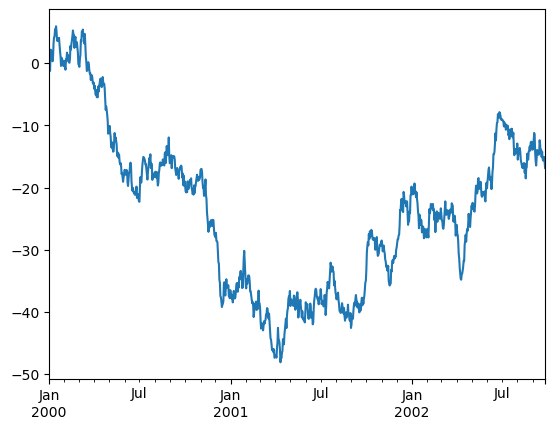

In [74]:
ts = pd.Series(np.random.randn(1000), index=pd.date_range('1/1/2000', periods=1000))
ts.cumsum().plot()

<Figure size 640x480 with 0 Axes>

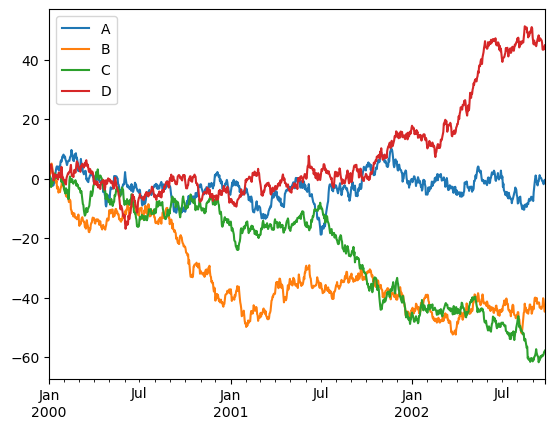

In [75]:
import matplotlib.pyplot as plt

pdf=pd.DataFrame(np.random.randn(1000, 4), index=ts.index,columns=['A', 'B', 'C', 'D'])
pdf = pdf.cumsum()
plt.figure(); pdf.plot(); plt.legend(loc='best')